# House Price Prediction 

In [ ]:
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, accuracy_score

### Load Dataset

In [ ]:
house = pd.read_csv(r'D:\VS code Files\Machine Learning\house_price_50k.csv')
house.head()

,area,bedrooms,bathrooms,floors,age,distance,garage,parking,garden,security,school_nearby,hospital_nearby,shopping_mall_nearby,public_transport,crime_rate,population_density,location,income_level,price
0,1360,6,2,2,9,10,0,0,1,0,1,0,1,0,6.939333,7242,premium,low,5.952493e+05
1,4272,5,2,3,24,8,1,0,0,1,1,1,1,0,0.400918,7729,low,low,1.571208e+06
2,3592,1,4,3,4,20,0,1,1,1,0,1,0,1,6.292386,1081,premium,mid,1.379943e+06
3,966,5,2,2,6,14,1,0,0,0,0,1,1,0,8.964112,8912,medium,low,4.367819e+05
4,4926,4,3,1,18,9,0,0,0,0,1,0,1,1,2.843309,8146,low,mid,1.792425e+06


In [ ]:
# Check shape
print("Shape of dataset:", house.shape)
print("="*50)

# Check info
print("General Information of Dataset:")
print(house.info())
print("="*50)

# Check datatypes

print("Data Type of each column:")
print(house.dtypes)
print("="*50)

# Check missing values
print("Missing valuse:")
print(house.isnull().sum())
print("="*50)

# Check duplicates
print("Duplicated rows:", house.duplicated().sum())



Shape of dataset: (50000, 19)
General Information of Dataset:
<class 'pandas.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 19 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   area                  50000 non-null  int64  
 1   bedrooms              50000 non-null  int64  
 2   bathrooms             50000 non-null  int64  
 3   floors                50000 non-null  int64  
 4   age                   50000 non-null  int64  
 5   distance              50000 non-null  int64  
 6   garage                50000 non-null  int64  
 7   parking               50000 non-null  int64  
 8   garden                50000 non-null  int64  
 9   security              50000 non-null  int64  
 10  school_nearby         50000 non-null  int64  
 11  hospital_nearby       50000 non-null  int64  
 12  shopping_mall_nearby  50000 non-null  int64  
 13  public_transport      50000 non-null  int64  
 14  crime_rate         

### Phase 2 — Exploratory Data Analysis

In [ ]:
# Mean
print("Columns wise Mean:")
print(np.mean(house.drop(columns=["location","income_level"]), axis=0).round(3))
print("="*50)

# Median
print("Column wise median:")
print(house.median(numeric_only=True).round(3))
print("="*50)

# Standard deviation
print("Standard Deviation of each column:")
print(house.std(numeric_only=True))


Columns wise Mean:
area                       2752.971
bedrooms                      3.496
bathrooms                     2.498
floors                        1.997
age                          19.574
distance                     14.969
garage                        0.501
parking                       0.497
garden                        0.500
security                      0.496
school_nearby                 0.501
hospital_nearby               0.498
shopping_mall_nearby          0.498
public_transport              0.500
crime_rate                    5.006
population_density         5065.946
price                   1030260.944
dtype: float64
Column wise median:
area                       2756.000
bedrooms                      3.000
bathrooms                     2.000
floors                        2.000
age                          20.000
distance                     15.000
garage                        1.000
parking                       0.000
garden                        1.000
security  

In [ ]:
# Correlation
print(house.corr(numeric_only=True))


                          area  bedrooms  bathrooms    floors       age  \
area                  1.000000  0.001620   0.004183 -0.005278  0.004143   
bedrooms              0.001620  1.000000  -0.000286  0.000257 -0.003006   
bathrooms             0.004183 -0.000286   1.000000 -0.001466  0.004041   
floors               -0.005278  0.000257  -0.001466  1.000000  0.005670   
age                   0.004143 -0.003006   0.004041  0.005670  1.000000   
distance              0.004628 -0.012233  -0.000902  0.005406  0.001270   
garage                0.000787 -0.011247  -0.008605 -0.001296 -0.002863   
parking               0.010964 -0.000562   0.001619 -0.001320 -0.000596   
garden                0.003350 -0.000092  -0.001753  0.002479 -0.001913   
security             -0.003673  0.004550   0.000649 -0.000493  0.008836   
school_nearby        -0.001165 -0.003885   0.003100 -0.007375 -0.001160   
hospital_nearby       0.013502 -0.002297   0.002571  0.000111 -0.002075   
shopping_mall_nearby -0.0

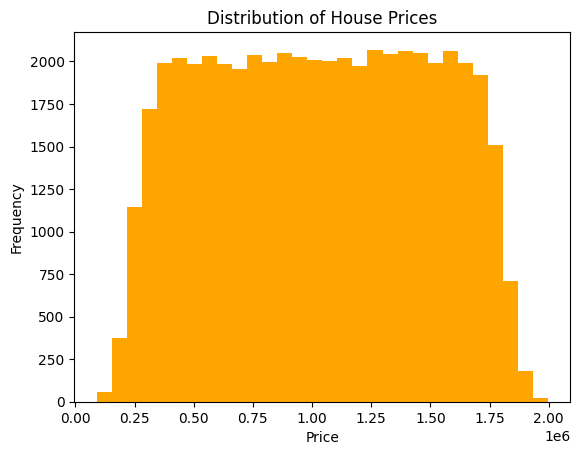

In [ ]:

# Distribution of target

import matplotlib.pyplot as plt

plt.hist(house["price"], bins=30, color='orange')
plt.xlabel("Price")
plt.ylabel("Frequency")
plt.title("Distribution of House Prices")
plt.show()


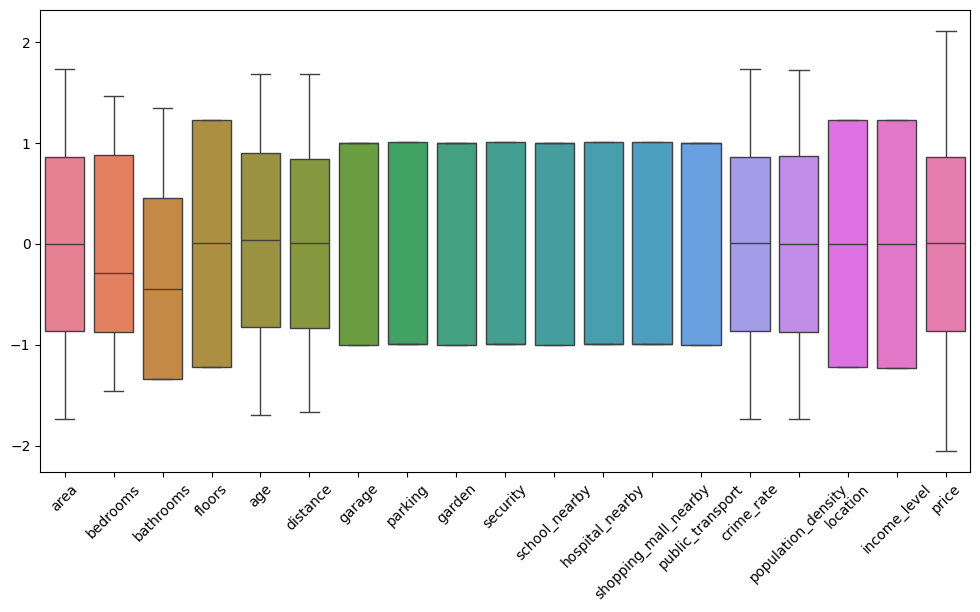

In [ ]:
# ----------------------------------------------------------------------------------------------------

from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()

cat_cols = ['location', 'income_level']

for cols in cat_cols:
    house[cols] = le.fit_transform(house[cols])
# ----------------------------------------------------------------------------------------------------

from sklearn.preprocessing import StandardScaler

std = StandardScaler()
X_scale = std.fit_transform(house)


X_scale = pd.DataFrame(X_scale,columns=house.columns)

plt.figure(figsize=(12,6))
sns.boxplot(data=X_scale.select_dtypes(include='number'))
plt.xticks(rotation=45)
plt.show()

<Axes: >

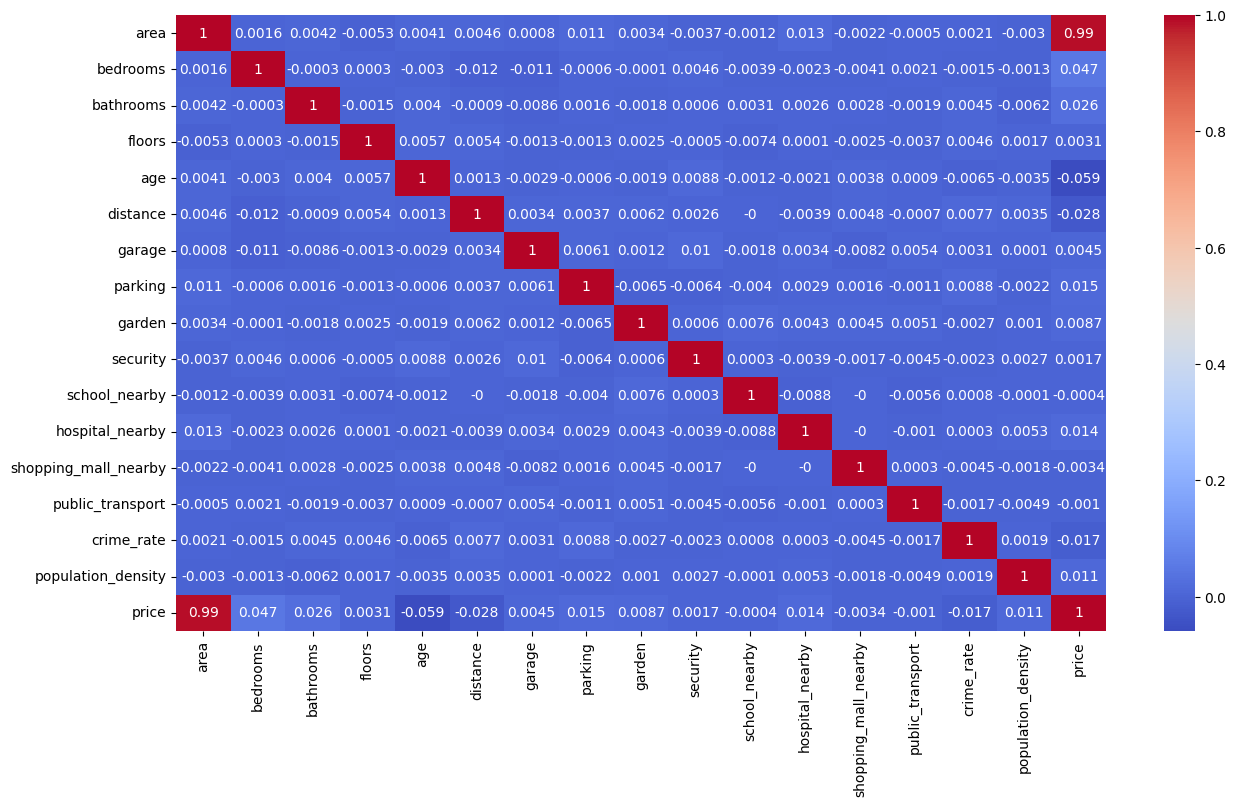

In [ ]:
plt.figure(figsize=(15,8))
sns.heatmap(
    house.drop(columns=["location","income_level"]).corr().round(4),
    annot=True,
    cmap="coolwarm"
)




<Axes: >

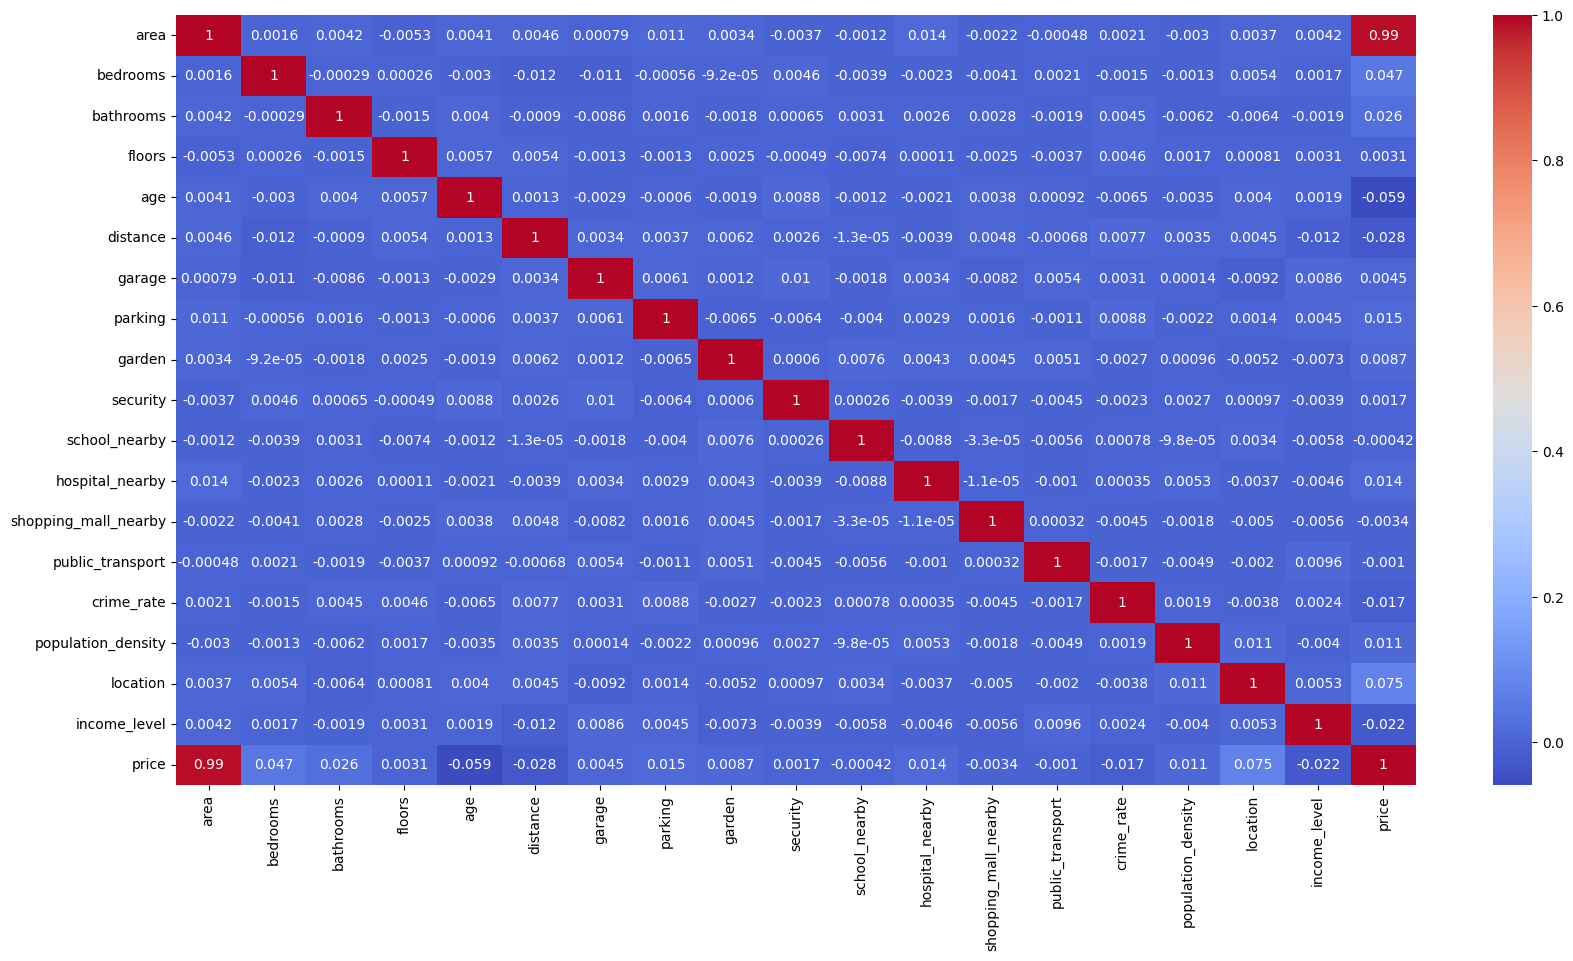

In [ ]:
plt.figure(figsize=(20,10))
sns.heatmap(house.corr(), annot=True, cmap="coolwarm")

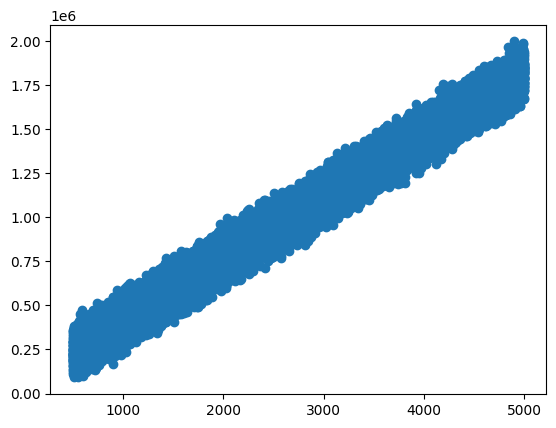

In [ ]:
plt.scatter(house['area'], house['price'])

### Data Cleaning

In [ ]:
# Missing values

house.isna().sum()  # no missing values

area                    0
bedrooms                0
bathrooms               0
floors                  0
age                     0
distance                0
garage                  0
parking                 0
garden                  0
security                0
school_nearby           0
hospital_nearby         0
shopping_mall_nearby    0
public_transport        0
crime_rate              0
population_density      0
location                0
income_level            0
price                   0
dtype: int64

In [ ]:
# Duplicate values
house.duplicated().sum()   # No dupicate rows.

np.int64(0)

In [ ]:
# Wrong datatypes
house.sample(3)


,area,bedrooms,bathrooms,floors,age,distance,garage,parking,garden,security,school_nearby,hospital_nearby,shopping_mall_nearby,public_transport,crime_rate,population_density,location,income_level,price
34232,4664,2,2,2,35,19,0,0,1,0,1,1,0,1,1.929732,1268,2,1,1.658919e+06
40942,1324,2,2,1,24,11,0,0,1,0,1,1,1,0,2.106968,261,1,0,4.788447e+05
33455,2761,2,3,2,13,4,1,1,0,0,0,0,1,1,1.598400,6764,1,2,1.076403e+06


In [ ]:
house.dtypes

area                      int64
bedrooms                  int64
bathrooms                 int64
floors                    int64
age                       int64
distance                  int64
garage                    int64
parking                   int64
garden                    int64
security                  int64
school_nearby             int64
hospital_nearby           int64
shopping_mall_nearby      int64
public_transport          int64
crime_rate              float64
population_density        int64
location                  int64
income_level              int64
price                   float64
dtype: object

In [ ]:
# Outlier treatment (optional)

### Feature Engineering

In [ ]:
# Phase 4 — 

# Convert categorical columns
# Label Encoding

# from sklearn.preprocessing import LabelEncoder

# le = LabelEncoder()

# cat_cols = ['location', 'income_level']

# for cols in cat_cols:
#     house[cols] = le.fit_transform(house[cols])


In [ ]:
X = house.drop(columns='price')
y = house['price']

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [ ]:
model = LinearRegression()
model.fit(X_train,y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [ ]:
y_pred = model.predict(X_test)

In [ ]:
y_train_pred = model.predict(X_train)

In [ ]:
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
import numpy as np

r2 = r2_score(y_test, y_pred)
r2_train = r2_score(y_train,y_train_pred)
print(r2_train)
print("R² Score :", r2)
print("MAE      :", mean_absolute_error(y_test, y_pred))
print("MSE      :", mean_squared_error(y_test, y_pred))
print("RMSE     :", np.sqrt(mean_squared_error(y_test, y_pred)))


n = X_train.shape[0]
p = X_train.shape[1]

# Adjusted R²
adjusted_r2 = 1 - (1 - r2) * (n - 1) / (n - p - 1)

print("Adjusted R²:", adjusted_r2)

0.9967820160787623
R² Score : 0.9968488990272465
MAE      : 20692.584282582404
MSE      : 663761366.6440895
RMSE     : 25763.56665223372
Adjusted R²: 0.9968474803579408


In [ ]:
print("Coefficient:",model.coef_)
print("Intercept:",model.intercept_)

Coefficient: [ 3.50057897e+02  1.19094554e+04  9.15511947e+03  5.14576257e+03
 -2.50174859e+03 -1.79086863e+03  4.67676745e+03  4.47479443e+03
  5.12766363e+03  4.97332014e+03  4.39207855e+02 -8.53421601e+01
 -5.59020715e+02 -1.79292840e+01 -3.03055112e+03  2.04912423e+00
  4.00971893e+04 -1.49416001e+04]
Intercept: 37812.96363842895


In [ ]:
coef = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": model.coef_
})

coef.sort_values("Coefficient", ascending=False)

,Feature,Coefficient
16,location,40097.189264
1,bedrooms,11909.455410
2,bathrooms,9155.119470
3,floors,5145.762575
8,garden,5127.663629
9,security,4973.320137
6,garage,4676.767450
7,parking,4474.794425
10,school_nearby,439.207855
0,area,350.057897
